# AI5707 Assignment 7: GMM models and pattern recognition
## Part 1: GMM per class on the Assignment 6 data

In [1]:

import os
import math
import random
import numpy as np
import matplotlib.pyplot as plt

cov_type = "Full"      # which Assignment 6 data to use: "Spherical", "Diagonal" or "Full"
max_iter = 100         # maximum EM iterations
tol = 1e-6             # stop EM when the log-likelihood barely changes
eps = 1e-6             # tiny number added to the covariance diagonal (keeps C invertible)

print("covariance type:", cov_type, "| max_iter:", max_iter, "| tol:", tol, "| eps:", eps)


covariance type: Full | max_iter: 100 | tol: 1e-06 | eps: 1e-06


In [3]:
# Cell 2: data generation (lab code, steps 1-8, unchanged)


import math
import random
import matplotlib.pyplot as plt

random.seed(42)

# STEP 1: Define the number of points and components
N = 1000
K = 3

# STEP 2: Define parameters for two classes
weights1 = [0.40, 0.35, 0.25]
means1 = [[-4, -2], [0, 3], [4, -1]]

weights2 = [0.30, 0.40, 0.30]
means2 = [[-3, 3], [1, -3], [5, 3]]


# STEP 3: Generate standard normal values using Box-Muller
def standard_normal():

    u1 = random.random()
    u2 = random.random()

    while u1 == 0:
        u1 = random.random()

    z1 = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
    z2 = math.sqrt(-2 * math.log(u1)) * math.sin(2 * math.pi * u2)

    return z1, z2


# STEP 4: Calculate Gaussian density N(x; mean, covariance)
# N(x; mu, C) = exp(-0.5 * quadratic) / (2*pi*sqrt(det(C)))

def gaussian_density(point, mean, covariance):

    a = covariance[0][0]
    b = covariance[0][1]
    c = covariance[1][1]

    determinant = a * c - b * b

    if determinant <= 0:
        raise ValueError("Covariance must be positive definite.")

    dx = point[0] - mean[0]
    dy = point[1] - mean[1]

    quadratic = (
        c * dx * dx - 2 * b * dx * dy + a * dy * dy
    ) / determinant

    return math.exp(-0.5 * quadratic) / (
        2 * math.pi * math.sqrt(determinant)
    )


# STEP 5: Implement the GMM formula
# p(x) = sum of weight_i * N(x; mean_i, covariance_i)

def gmm_density(point, weights, means, covariances):

    density = 0.0

    for i in range(K):
        density += weights[i] * gaussian_density(
            point, means[i], covariances[i]
        )

    return density


# STEP 6: Generate data from one Gaussian component
# Use the covariance matrix to scale and correlate z1 and z2.

def generate_gaussian(mean, covariance):

    z1, z2 = standard_normal()

    a = covariance[0][0]
    b = covariance[0][1]
    c = covariance[1][1]

    if a <= 0 or c - b * b / a <= 0:
        raise ValueError("Covariance must be positive definite.")

    x = mean[0] + math.sqrt(a) * z1

    y = (
        mean[1]
        + (b / math.sqrt(a)) * z1
        + math.sqrt(c - b * b / a) * z2
    )

    return [x, y]


# STEP 7: Generate GMM data using mixture-weight ranges

def generate_data(N, weights, means, covariances):

    data = []
    component_labels = []

    for _ in range(N):

        u = random.random()

        if u < weights[0]:
            component = 0
        elif u < weights[0] + weights[1]:
            component = 1
        else:
            component = 2

        point = generate_gaussian(
            means[component],
            covariances[component]
        )

        data.append(point)
        component_labels.append(component)

    return data, component_labels


# STEP 8: Define spherical, diagonal and full covariance matrices

covariance_types = {

    "Spherical": [
        [[1, 0], [0, 1]],
        [[1, 0], [0, 1]],
        [[1, 0], [0, 1]]
    ],

    "Diagonal": [
        [[2, 0], [0, 0.5]],
        [[0.5, 0], [0, 2]],
        [[1.5, 0], [0, 0.7]]
    ],

    "Full": [
        [[2, 0.8], [0.8, 1]],
        [[1.5, -0.6], [-0.6, 1]],
        [[1, 0.5], [0.5, 1.5]]
    ]
}


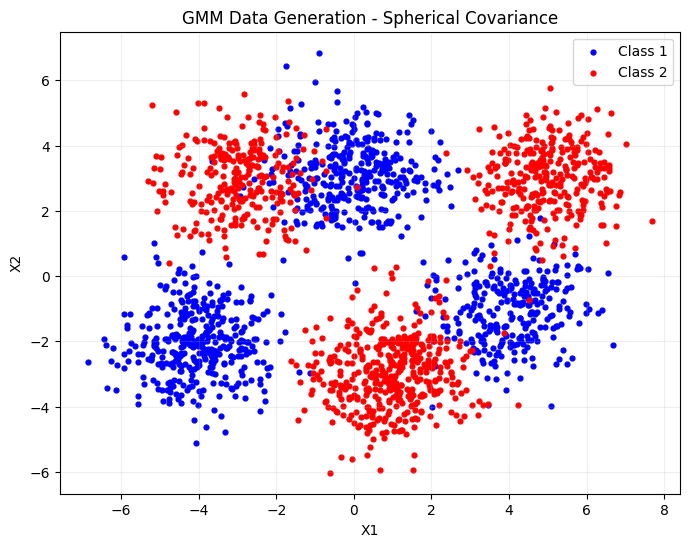


Covariance type: Spherical
Class 1 points: 1000
Class 2 points: 1000
GMM density for Class 1 at (0, 0): 0.000629804097616018
GMM density for Class 2 at (0, 0): 0.00043484538925683716


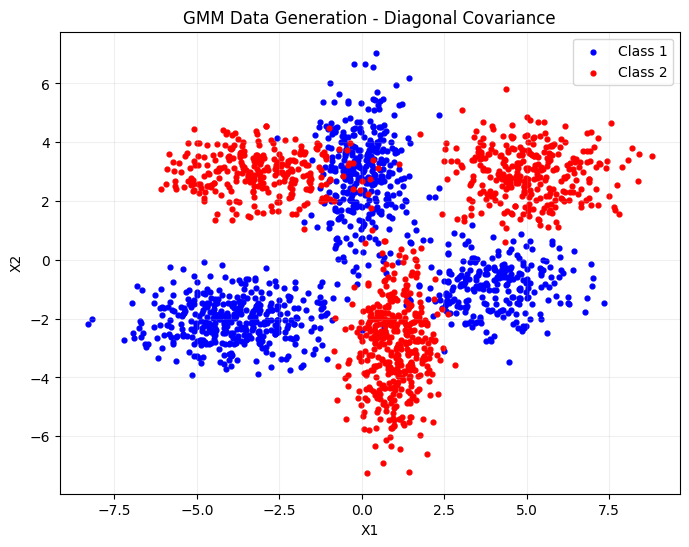


Covariance type: Diagonal
Class 1 points: 1000
Class 2 points: 1000
GMM density for Class 1 at (0, 0): 0.0059843124995902315
GMM density for Class 2 at (0, 0): 0.0024690818746732493


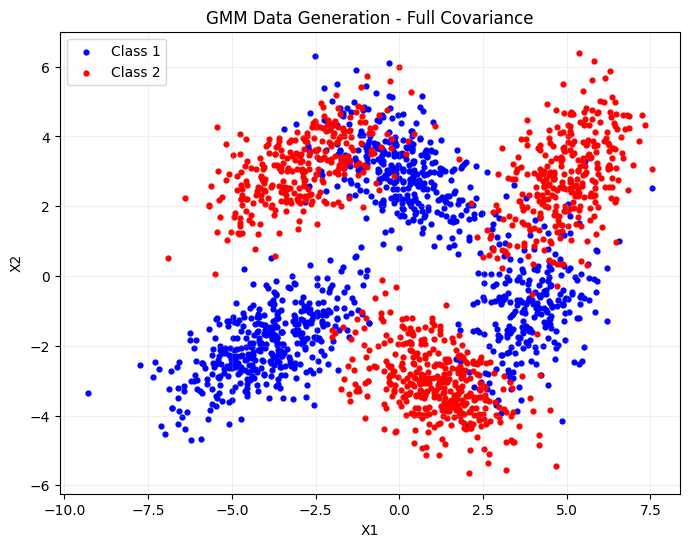


Covariance type: Full
Class 1 points: 1000
Class 2 points: 1000
GMM density for Class 1 at (0, 0): 0.001029142616259974
GMM density for Class 2 at (0, 0): 0.0005004135046810577


In [4]:
# Cell 3: data generation (lab code, step 9, unchanged): generates and plots all 3 covariance types

# STEP 9: Generate and plot both classes for each covariance type

generated_data = {}

for name, covariances in covariance_types.items():

    class1, labels1 = generate_data(
        N, weights1, means1, covariances
    )

    class2, labels2 = generate_data(
        N, weights2, means2, covariances
    )

    generated_data[name] = {
        "Class 1": class1,
        "Class 2": class2,
        "Labels 1": labels1,
        "Labels 2": labels2
    }

    # Plot the two classes in different colours
    plt.figure(figsize=(8, 6))

    plt.scatter(
        [p[0] for p in class1],
        [p[1] for p in class1],
        color="blue", s=12, label="Class 1"
    )

    plt.scatter(
        [p[0] for p in class2],
        [p[1] for p in class2],
        color="red", s=12, label="Class 2"
    )

    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title("GMM Data Generation - " + name + " Covariance")
    plt.legend()
    plt.grid(True, alpha=0.2)
    plt.show()

    # Verify the explicit GMM density formula
    print("\nCovariance type:", name)
    print("Class 1 points:", len(class1))
    print("Class 2 points:", len(class2))

    print(
        "GMM density for Class 1 at (0, 0):",
        gmm_density([0, 0], weights1, means1, covariances)
    )

    print(
        "GMM density for Class 2 at (0, 0):",
        gmm_density([0, 0], weights2, means2, covariances)
    )


In [5]:
# Cell 4: pick one covariance type, convert to numpy, 80% train / 20% test per class

X1 = np.array(generated_data[cov_type]["Class 1"])
X2 = np.array(generated_data[cov_type]["Class 2"])

X1_train, X1_test = X1[:800], X1[800:]
X2_train, X2_test = X2[:800], X2[800:]

print("Class 1 train/test:", X1_train.shape, X1_test.shape)
print("Class 2 train/test:", X2_train.shape, X2_test.shape)


Class 1 train/test: (800, 2) (200, 2)
Class 2 train/test: (800, 2) (200, 2)


In [6]:
# Cell 5: the formulas
#   N(x; mu, C) = (2*pi)^(-d/2) * |C|^(-1/2) * exp( -1/2 (x-mu)^T C^-1 (x-mu) )
#   p(x)        = sum_k pi_k * N(x; mu_k, C_k)
# Both are computed in log form so that small densities do not underflow.

def log_gaussian(X, mu, C):
    d = len(mu)
    diff = X - mu
    quad = np.sum((diff @ np.linalg.inv(C)) * diff, axis=1)       # (x-mu)^T C^-1 (x-mu)
    return -0.5 * d * np.log(2 * np.pi) - 0.5 * np.log(np.linalg.det(C)) - 0.5 * quad

def log_gmm(X, pi, mu, C):
    # terms[n, k] = log( pi_k * N(x_n; mu_k, C_k) )
    terms = np.stack([np.log(pi[k]) + log_gaussian(X, mu[k], C[k]) for k in range(len(pi))], axis=1)
    m = terms.max(axis=1, keepdims=True)
    log_p = m[:, 0] + np.log(np.exp(terms - m).sum(axis=1))      # log sum_k exp(terms)
    return log_p, terms

# Test: my formula must match the lab's gaussian_density at (0, 0)
mine = np.exp(log_gaussian(np.array([[0.0, 0.0]]), np.array(means1[0], float),
                           np.array(covariance_types[cov_type][0], float)))[0]
lab_value = gaussian_density([0, 0], means1[0], covariance_types[cov_type][0])
print("mine:", mine, "| lab:", lab_value)


mine: 0.002222180239635488 | lab: 0.0022221802396354866


In [7]:
# Cell 6: EM algorithm for a GMM
#   E-step: gamma_nk = pi_k N(x_n; mu_k, C_k) / sum_j pi_j N(x_n; mu_j, C_j)
#   M-step: N_k  = sum_n gamma_nk
#           mu_k = (1/N_k) sum_n gamma_nk x_n
#           C_k  = (1/N_k) sum_n gamma_nk (x_n - mu_k)(x_n - mu_k)^T
#           pi_k = N_k / N

def fit_gmm(X, K, eps, max_iter, tol):
    n, d = X.shape

    # initial values: K random training points as means, whole-class covariance, equal weights
    idx = []
    while len(idx) < K:
        i = int(random.random() * n)
        if i not in idx:
            idx.append(i)
    mu = X[idx].copy()
    m = X.mean(axis=0)
    C0 = (X - m).T @ (X - m) / n + eps * np.eye(d)
    C = np.array([C0 for k in range(K)])
    pi = np.ones(K) / K

    history = []                                    # log-likelihood after each iteration
    for it in range(max_iter):
        # E-step
        log_p, terms = log_gmm(X, pi, mu, C)
        gamma = np.exp(terms - log_p[:, None])
        history.append(log_p.sum())

        # M-step
        Nk = gamma.sum(axis=0)
        pi = Nk / n
        mu = (gamma.T @ X) / Nk[:, None]
        for k in range(K):
            diff = X - mu[k]
            C[k] = (gamma[:, k, None] * diff).T @ diff / Nk[k] + eps * np.eye(d)

        if it > 0 and abs(history[-1] - history[-2]) < tol * abs(history[-2]):
            break

    return pi, mu, C, history

print("fit_gmm defined")


fit_gmm defined


Class 1 - iterations: 23
  estimated weights: [0.4  0.25 0.35] | true weights: [0.4, 0.35, 0.25]
  estimated means:
 [[-3.97 -1.96]
 [ 3.92 -0.91]
 [ 0.14  2.96]]
  true means: [[-4, -2], [0, 3], [4, -1]]
Class 2 - iterations: 14
  estimated weights: [0.38 0.29 0.32] | true weights: [0.3, 0.4, 0.3]
  estimated means:
 [[ 1.07 -3.06]
 [-2.87  3.09]
 [ 4.95  2.81]]
  true means: [[-3, 3], [1, -3], [5, 3]]


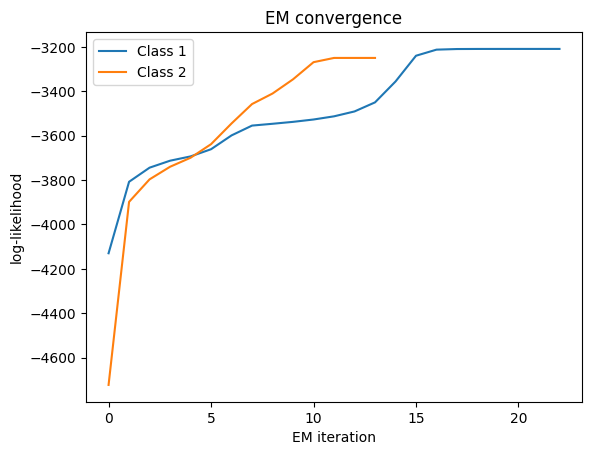

In [8]:
# Cell 7: build one GMM per class using the 80% training data

random.seed(1)                                      # same start every time this cell is run
model1 = fit_gmm(X1_train, K, eps, max_iter, tol)   # K = 3 comes from the lab code
model2 = fit_gmm(X2_train, K, eps, max_iter, tol)

for name_c, model, w_true, m_true in [("Class 1", model1, weights1, means1),
                                      ("Class 2", model2, weights2, means2)]:
    print(name_c, "- iterations:", len(model[3]))
    print("  estimated weights:", np.round(model[0], 2), "| true weights:", w_true)
    print("  estimated means:\n", np.round(model[1], 2))
    print("  true means:", m_true)

plt.plot(model1[3], label="Class 1")
plt.plot(model2[3], label="Class 2")
plt.xlabel("EM iteration")
plt.ylabel("log-likelihood")
plt.title("EM convergence")
plt.legend()
plt.show()


In [9]:
# Cell 8: classify the 20% test data: choose the class with the larger log p(x | class)

X_test = np.vstack([X1_test, X2_test])
true = np.array([0] * len(X1_test) + [1] * len(X2_test))

score1 = log_gmm(X_test, model1[0], model1[1], model1[2])[0]
score2 = log_gmm(X_test, model2[0], model2[1], model2[2])[0]
pred = np.where(score1 > score2, 0, 1)

cm1 = np.zeros((2, 2), dtype=int)                   # rows = true class, columns = predicted class
for t, p in zip(true, pred):
    cm1[t, p] += 1

print("Confusion matrix (rows = true, columns = predicted; order: Class 1, Class 2)")
print(cm1)
print("Accuracy:", np.trace(cm1) / cm1.sum())


Confusion matrix (rows = true, columns = predicted; order: Class 1, Class 2)
[[183  17]
 [ 17 183]]
Accuracy: 0.915


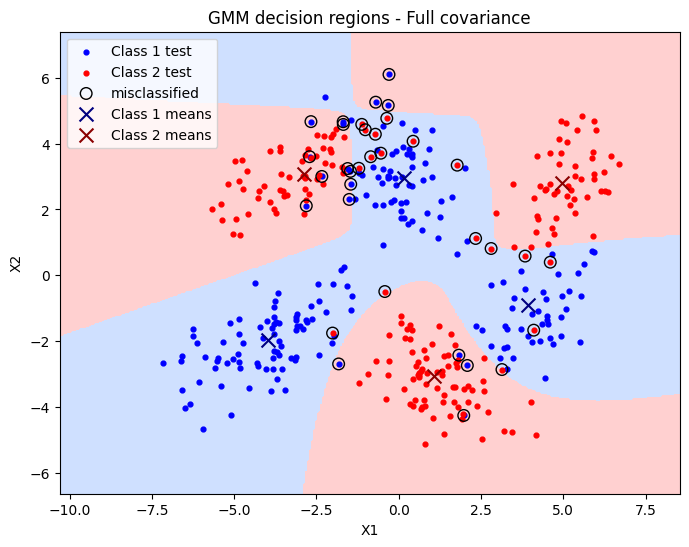

In [10]:
# Cell 9: decision regions of the two GMMs with the test points on top

X_all = np.vstack([X1, X2])
gx, gy = np.meshgrid(np.linspace(X_all[:, 0].min() - 1, X_all[:, 0].max() + 1, 300),
                     np.linspace(X_all[:, 1].min() - 1, X_all[:, 1].max() + 1, 300))
grid = np.c_[gx.ravel(), gy.ravel()]

g1 = log_gmm(grid, model1[0], model1[1], model1[2])[0]
g2 = log_gmm(grid, model2[0], model2[1], model2[2])[0]
region = np.where(g1 > g2, 0, 1).reshape(gx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(gx, gy, region, levels=[-0.5, 0.5, 1.5], colors=["#cfe0ff", "#ffd0d0"])
plt.scatter(X1_test[:, 0], X1_test[:, 1], color="blue", s=12, label="Class 1 test")
plt.scatter(X2_test[:, 0], X2_test[:, 1], color="red", s=12, label="Class 2 test")
wrong = X_test[pred != true]
plt.scatter(wrong[:, 0], wrong[:, 1], facecolors="none", edgecolors="black", s=70, label="misclassified")
plt.scatter(model1[1][:, 0], model1[1][:, 1], marker="x", color="navy", s=100, label="Class 1 means")
plt.scatter(model2[1][:, 0], model2[1][:, 1], marker="x", color="darkred", s=100, label="Class 2 means")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM decision regions - " + cov_type + " covariance")
plt.legend()
plt.show()


**Observations (Part 1)** - write after running: accuracy, where the misclassified points lie relative to the boundary, and how the estimated means and weights compare with the true ones.

## Part 2: GMM per digit on MNIST (digits 2, 5, 7)

In [11]:
# Cell 11: load the MNIST images of our 3 digits (train and test)
# plt.imread gives PNG pixels already scaled to 0..1, so no division by 255 is needed.

data_dir = os.path.join(r"C:\Users\KUZHALAMANI\MY JUPYTER NOTEBOOK\assignment 7", "TEAM_20")
digits = [2, 5, 7]

print(os.listdir(data_dir))                         # expect: dev, test, train

def load_split(split):
    out = {}
    for d in digits:
        folder = os.path.join(data_dir, split, str(d))
        files = sorted(f for f in os.listdir(folder) if f.endswith(".png"))
        out[d] = np.array([plt.imread(os.path.join(folder, f)).reshape(784) for f in files])
    return out

train_raw = load_split("train")
test_raw = load_split("test")

for d in digits:
    print("digit", d, "| train:", train_raw[d].shape, "| test:", test_raw[d].shape)


['dev', 'test', 'train']
digit 2 | train: (4762, 784) | test: (1032, 784)
digit 5 | train: (4368, 784) | test: (892, 784)
digit 7 | train: (4983, 784) | test: (1028, 784)


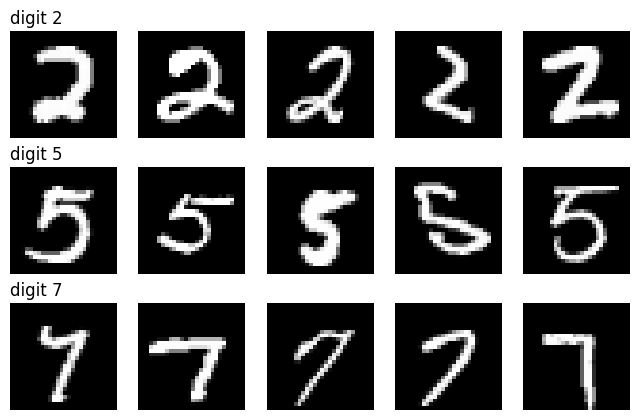

In [13]:
# Cell 12: look at a few images of each digit

fig, axes = plt.subplots(3, 5, figsize=(8, 5))
for r, d in enumerate(digits):
    for c in range(5):
        axes[r, c].imshow(train_raw[d][c].reshape(28, 28), cmap="gray")
        axes[r, c].axis("off")
    axes[r, 0].set_title("digit " + str(d), loc="left")
plt.show()


digit 2 | train: (4762, 49) | test: (1032, 49)
digit 5 | train: (4368, 49) | test: (892, 49)
digit 7 | train: (4983, 49) | test: (1028, 49)


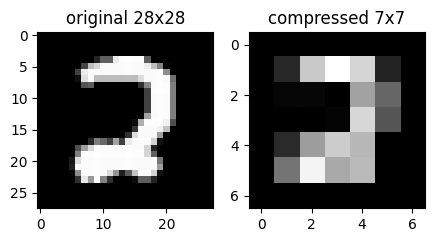

In [18]:
# Cell 13: compress each image: average every 4x4 block of pixels, 28x28 -> 7x7 = 49 features

def compress(X):
    return X.reshape(-1, 7, 4, 7, 4).mean(axis=(2, 4)).reshape(len(X), 49)

train_p = {d: compress(train_raw[d]) for d in digits}
test_p = {d: compress(test_raw[d]) for d in digits}

for d in digits:
    print("digit", d, "| train:", train_p[d].shape, "| test:", test_p[d].shape)

fig, axes = plt.subplots(1, 2, figsize=(5, 3))
axes[0].imshow(train_raw[2][0].reshape(28, 28), cmap="gray")
axes[0].set_title("original 28x28")
axes[1].imshow(train_p[2][0].reshape(7, 7), cmap="gray")
axes[1].set_title("compressed 7x7")
plt.show()


digit 2 | iterations: 49 | weights: [0.39 0.46 0.15] | smallest det(C): 5.9451344078293595e-114
digit 5 | iterations: 100 | weights: [0.59 0.29 0.12] | smallest det(C): 4.971901772873235e-118
digit 7 | iterations: 54 | weights: [0.56 0.16 0.27] | smallest det(C): 4.124288432058041e-122


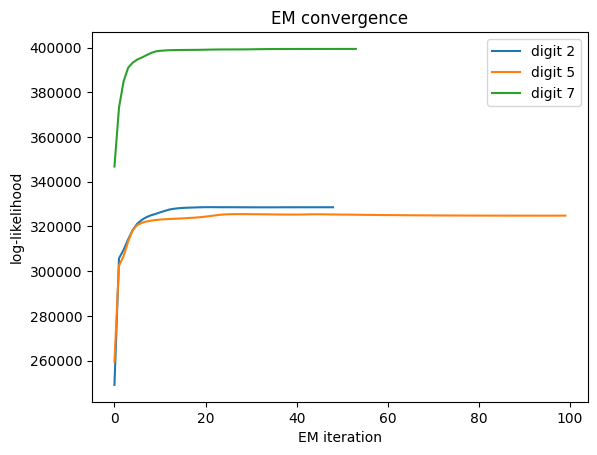

In [19]:
# Cell 14: build one GMM per digit using ONLY the training data (same fit_gmm as Part 1)

K_digits = 3            # components per digit
eps_digits = 1e-3       # larger than Part 1: some pooled pixels are always 0, which would make C singular

random.seed(1)
models = {d: fit_gmm(train_p[d], K_digits, eps_digits, max_iter, tol) for d in digits}

for d in digits:
    dets = [np.linalg.det(C) for C in models[d][2]]
    print("digit", d, "| iterations:", len(models[d][3]),
          "| weights:", np.round(models[d][0], 2), "| smallest det(C):", min(dets))

for d in digits:
    plt.plot(models[d][3], label="digit " + str(d))
plt.xlabel("EM iteration")
plt.ylabel("log-likelihood")
plt.title("EM convergence")
plt.legend()
plt.show()


In [21]:
# Cell 15: classify the test images: choose the digit with the largest log p(x | digit)

X_test_d = np.vstack([test_p[d] for d in digits])
X_test_raw = np.vstack([test_raw[d] for d in digits])                  # original images, used later for plotting
true_d = np.concatenate([[i] * len(test_p[d]) for i, d in enumerate(digits)])

scores = np.stack([log_gmm(X_test_d, models[d][0], models[d][1], models[d][2])[0] for d in digits], axis=1)
pred_d = scores.argmax(axis=1)

cm3 = np.zeros((3, 3), dtype=int)                   # rows = true digit, columns = predicted digit
for t, p in zip(true_d, pred_d):
    cm3[t, p] += 1

print("Confusion matrix (rows = true, columns = predicted; order:", digits, ")")
print(cm3)
print("Accuracy:", np.trace(cm3) / cm3.sum())


Confusion matrix (rows = true, columns = predicted; order: [2, 5, 7] )
[[1017    4   11]
 [   7  879    6]
 [  14    1 1013]]
Accuracy: 0.9854336043360433


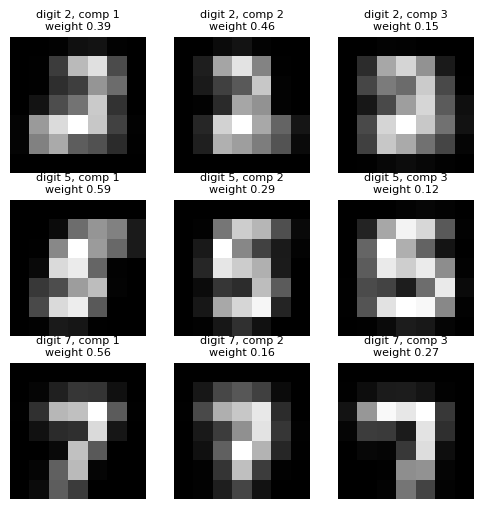

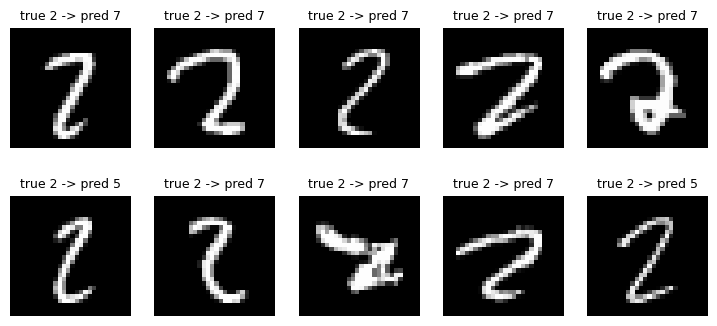

Most confused: true 7 predicted as 2 -> 14 images


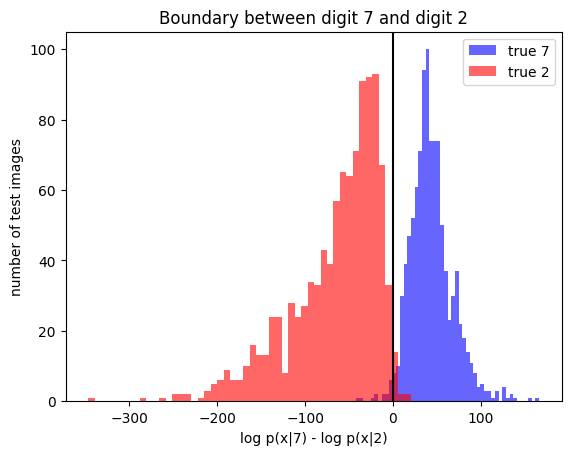

In [22]:
# Cell 16: explain the confusions with the trained GMMs

# (a) what each component learned: its mean image (7x7)
fig, axes = plt.subplots(3, K_digits, figsize=(6, 6))
for r, d in enumerate(digits):
    for k in range(K_digits):
        axes[r, k].imshow(models[d][1][k].reshape(7, 7), cmap="gray")
        axes[r, k].set_title("digit " + str(d) + ", comp " + str(k + 1) + "\nweight " + str(round(models[d][0][k], 2)), fontsize=8)
        axes[r, k].axis("off")
plt.show()

# (b) some misclassified test images
wrong_idx = np.where(pred_d != true_d)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, n in zip(axes.ravel(), wrong_idx):
    ax.imshow(X_test_raw[n].reshape(28, 28), cmap="gray")
    ax.set_title("true " + str(digits[true_d[n]]) + " -> pred " + str(digits[pred_d[n]]), fontsize=9)
    ax.axis("off")
plt.show()

# (c) the most confused pair: true digit A predicted as digit B
off = cm3.copy()
np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
A, B = digits[i], digits[j]
print("Most confused: true", A, "predicted as", B, "->", off[i, j], "images")

# s = log p(x|A) - log p(x|B). The decision boundary is s = 0.
s = scores[:, i] - scores[:, j]
plt.hist(s[true_d == i], bins=50, alpha=0.6, color="blue", label="true " + str(A))
plt.hist(s[true_d == j], bins=50, alpha=0.6, color="red", label="true " + str(B))
plt.axvline(0, color="black")
plt.xlabel("log p(x|" + str(A) + ") - log p(x|" + str(B) + ")")
plt.ylabel("number of test images")
plt.title("Boundary between digit " + str(A) + " and digit " + str(B))
plt.legend()
plt.show()


In [20]:
for name in ["fit_gmm", "log_gmm", "max_iter", "tol", "train_p", "test_p", "digits", "K_digits", "eps_digits", "models"]:
    print(name, name in globals())

fit_gmm True
log_gmm True
max_iter True
tol True
train_p True
test_p True
digits True
K_digits True
eps_digits True
models True


**Observations (Part 2)** - write after running: test accuracy, which digits are confused most, what the component mean images show, and how far the two histograms overlap around the boundary.